# 04.1 SVM: búsqueda de hiperparámetros (experimento 1)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en `README.md`)

Instrucciones:

- La búsqueda usa Optuna con `N_TRIALS` pruebas y la misma validación en todos los modelos: 5 grupos separados por animal y la semilla `SEED`.
- Nombre de los archivos que se generan: `svm_clf` y `svm_reg`. Es el primer argumento de `tune(...)`, y el notebook de modelado lo usa en `load_best(...)`.
- Se hace con `tune(...)` de `tuning.py`. Solo hay que definir `make_pipe` (el pipeline) y `space` (qué ajustes se prueban y en qué rango).
- En modelos lentos se puede usar `subsample=0.2` (el 20 % de los animales).
- Si cambian las variables o los datos, hay que repetir la búsqueda. El notebook de modelado lo comprueba.
- No usar `test`.

In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, SVR

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, FEATURES, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]

/Users/klorenzoe/Documents/Personal/MUCSI/ML/mucsi-ml-animal-shelter-project/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

- `AVAILABLE`: las 22 variables de `dev_features.csv`.
- `FEATURES_EXP1_CLF` y `FEATURES_EXP1_REG`: variables del experimento 1 para este modelo, en clasificación y en regresión.

In [3]:
AVAILABLE = FEATURES
FEATURES_EXP1_CLF = CAT_LOW + BINARY + NUMERIC
FEATURES_EXP1_REG = CAT_LOW + BINARY + NUMERIC

print("El experimento 1 usa estas variables:")
print("Clasificación:", FEATURES_EXP1_CLF)
print("Regresión:", FEATURES_EXP1_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 1 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


## Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `C` | Qué tan estricto es el modelo con los errores. Bajo: más flexible y simple. Alto: se pega más a los datos de entrenamiento. | 0,01 a 100 |
| `gamma` | Qué tan cerca deben estar dos animales para considerarse parecidos. Bajo: modelo más suave. Alto: se fija en detalles y puede aprenderse los datos de memoria. | 0,0001 a 1 |
| `class_weight` | Solo en clasificación. `balanced` da más peso a las clases pequeñas, `None` trata a todas igual. | `None` o `balanced` |
| `epsilon` | Solo en regresión. Diferencia que el modelo tolera sin contarla como error. | 0,01 a 0,5 |

`C`, `gamma` y `epsilon` se prueban en escala logarítmica: así se exploran por igual valores pequeños y grandes.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1.

Búsqueda de SVM (clasificación): 20 pruebas con 12,729 filas y 11,512 animales.
Prueba 1/20: resultado 0.240 | mejor hasta ahora 0.240
Prueba 2/20: resultado 0.025 | mejor hasta ahora 0.240
Prueba 3/20: resultado 0.480 | mejor hasta ahora 0.480
Prueba 4/20: resultado 0.422 | mejor hasta ahora 0.480
Prueba 5/20: resultado 0.413 | mejor hasta ahora 0.480
Prueba 6/20: resultado 0.410 | mejor hasta ahora 0.480
Prueba 7/20: resultado 0.477 | mejor hasta ahora 0.480
Prueba 8/20: resultado 0.216 | mejor hasta ahora 0.480
Prueba 9/20: resultado 0.120 | mejor hasta ahora 0.480
Prueba 10/20: resultado 0.120 | mejor hasta ahora 0.480
Prueba 11/20: resultado 0.472 | mejor hasta ahora 0.480
Prueba 12/20: resultado 0.490 | mejor hasta ahora 0.490
Prueba 13/20: resultado 0.452 | mejor hasta ahora 0.490
Prueba 14/20: resultado 0.419 | mejor hasta ahora 0.490
Prueba 15/20: resultado 0.480 | mejor hasta ahora 0.490
Prueba 16/20: resultado 0.457 | mejor hasta ahora 0.490
Prueba 17/20: resultado 0.487 | m

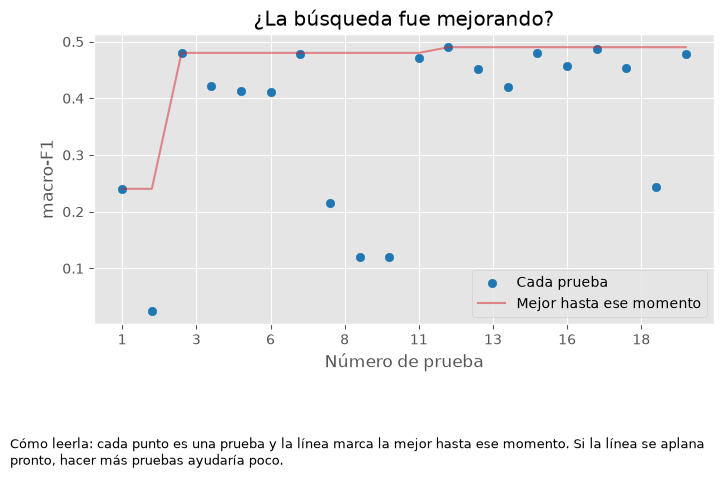

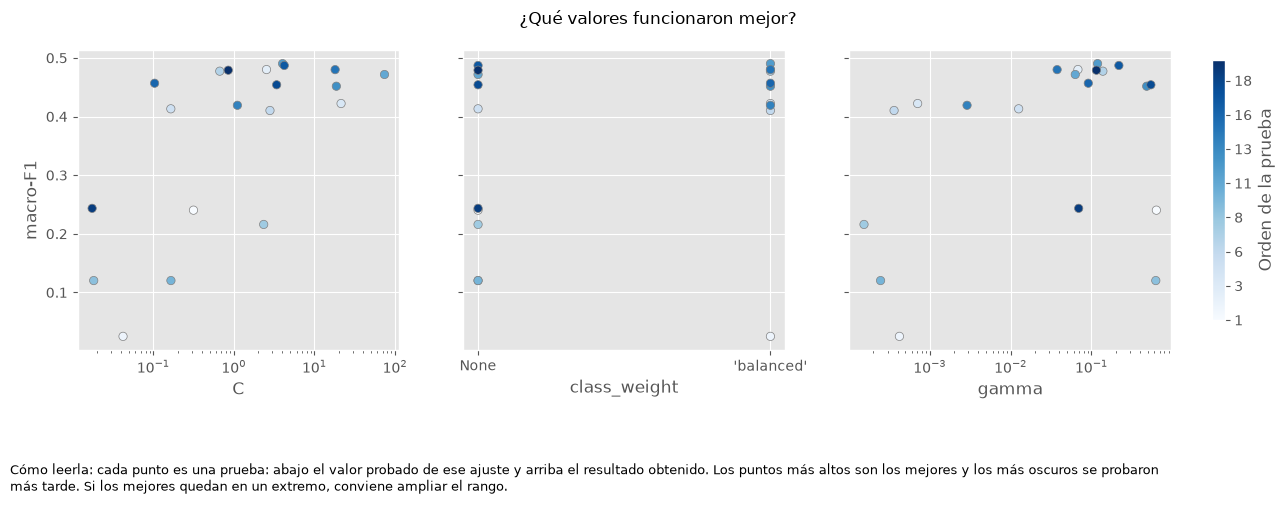

In [4]:
def make_pipe_clf(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_CLF)),
                     ("model", SVC(**params))])

def space_clf(trial):
    return {"C": trial.suggest_float("C", 1e-2, 1e2, log=True),
            "gamma": trial.suggest_float("gamma", 1e-4, 1, log=True),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

study_clf = tune(
    "svm_clf", make_pipe_clf, space_clf, data[FEATURES_EXP1_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP1_CLF, model_label="SVM", task_label="clasificación",
    params_help={"C": "Qué tan estricto es el modelo con los errores (alto = más estricto).",
                 "gamma": "Qué tan cerca deben estar dos animales para considerarse parecidos (alto = más detalle).",
                 "class_weight": "balanced da más peso a las clases pequeñas."},
    n_trials=N_TRIALS, subsample=0.2)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log.

Búsqueda de SVM (regresión): 20 pruebas con 27,073 filas y 24,720 animales.
Prueba 1/20: resultado 0.181 | mejor hasta ahora 0.181
Prueba 2/20: resultado 0.120 | mejor hasta ahora 0.181
Prueba 3/20: resultado 0.135 | mejor hasta ahora 0.181
Prueba 4/20: resultado 0.146 | mejor hasta ahora 0.181
Prueba 5/20: resultado 0.139 | mejor hasta ahora 0.181
Prueba 6/20: resultado 0.086 | mejor hasta ahora 0.181
Prueba 7/20: resultado 0.125 | mejor hasta ahora 0.181
Prueba 8/20: resultado 0.061 | mejor hasta ahora 0.181
Prueba 9/20: resultado 0.181 | mejor hasta ahora 0.181
Prueba 10/20: resultado 0.174 | mejor hasta ahora 0.181
Prueba 11/20: resultado 0.209 | mejor hasta ahora 0.209
Prueba 12/20: resultado 0.213 | mejor hasta ahora 0.213
Prueba 13/20: resultado 0.200 | mejor hasta ahora 0.213
Prueba 14/20: resultado 0.167 | mejor hasta ahora 0.213
Prueba 15/20: resultado 0.140 | mejor hasta ahora 0.213
Prueba 16/20: resultado 0.193 | mejor hasta ahora 0.213
Prueba 17/20: resultado 0.168 | mejor

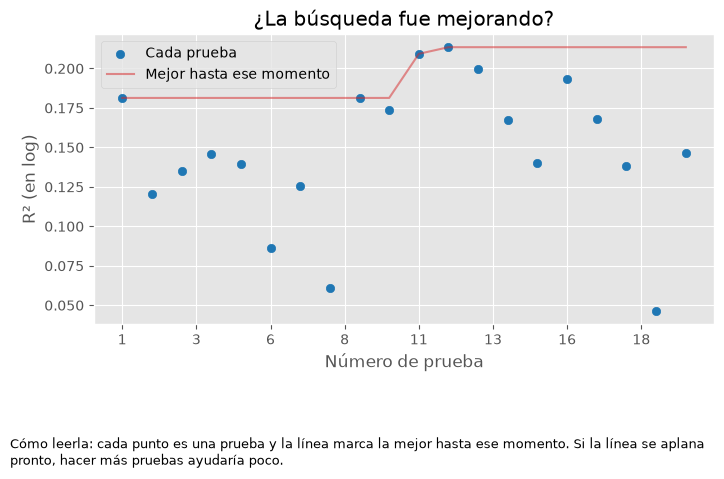

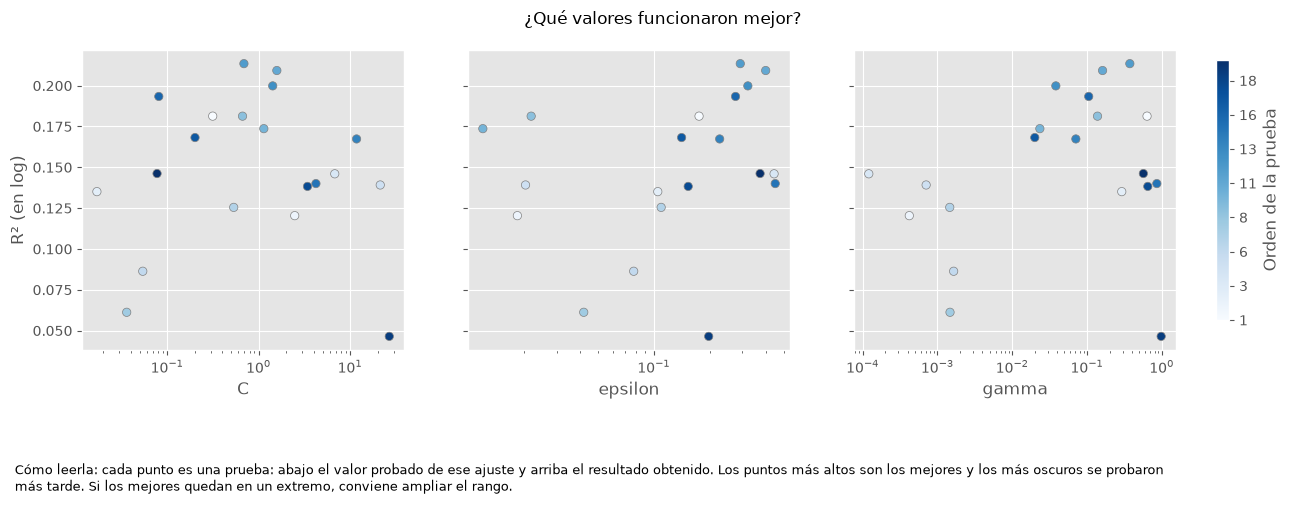

In [5]:
def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_REG)),
                     ("model", SVR(**params))])

def space_reg(trial):
    return {"C": trial.suggest_float("C", 1e-2, 1e2, log=True),
            "gamma": trial.suggest_float("gamma", 1e-4, 1, log=True),
            "epsilon": trial.suggest_float("epsilon", 1e-2, 0.5, log=True)}

study_reg = tune(
    "svm_reg", make_pipe_reg, space_reg, data.loc[adopted, FEATURES_EXP1_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP1_REG, model_label="SVM", task_label="regresión",
    params_help={"C": "Qué tan estricto es el modelo con los errores (alto = más estricto).",
                 "gamma": "Qué tan cerca deben estar dos animales para considerarse parecidos (alto = más detalle).",
                 "epsilon": "Diferencia que el modelo tolera sin contarla como error."},
    n_trials=N_TRIALS)